# Tree-based models: Random Forest, XGBoost, LightGBM

CRISP-DM phase 4/5, research question 1: **do tree-based models forecast weekly meal demand better than the
baselines?** The bar to beat is Linear Regression from notebook 04 (WAPE 32.0%).

Same folds, same features, same metrics as notebook 04, so the results can be compared directly.

How the models are tuned (inside each fold, training weeks only):
- the last 10 training weeks are used as a **validation period** (the same split as a fold, just 10 weeks earlier)
- a few settings are tried on it, the best one is kept
- LightGBM and XGBoost use **early stopping**: keep adding trees until the validation error stops improving
- then the model is trained again on all training weeks and tested on the 10 test weeks

Training all models takes about 30-45 min. Set `RUN_TRAINING = False` to load the saved predictions instead.

In [1]:
import sys
sys.path.append('..')
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor

from src.features import build_dataset, FEATURES
from src.folds import ORIGINS, split_fold
from src.metrics import all_metrics, wape, diebold_mariano
from src.plot_settings import set_ieee_style, save_fig, ONE_COL, TWO_COL

set_ieee_style()
pd.set_option('display.max_columns', 30)

RUN_TRAINING = True
SEED = 42

# lightgbm prints a long 'eval_set is deprecated' warning on every fit, hide it
warnings.filterwarnings('ignore', message='.*eval_set.*')

## 1. Load data

In [2]:
df = pd.read_parquet('../data/processed/clean.parquet')
hist = pd.read_parquet('../data/processed/history_features.parquet')
data = build_dataset(df, hist)

# ids are labels, not numbers -> category type so the trees treat them as groups
for col in ['center_id', 'meal_id', 'city_code', 'region_code']:
    data[col] = data[col].astype('category')

print(data.shape)
print(len(FEATURES), 'features')

(4407292, 32)
25 features


## 2. Training functions

One function per model. Each one gets the training rows of a fold, tunes on the last 10 training weeks,
retrains on all training rows and returns the forecasts for the test rows (in number of orders).

In [3]:
def inner_split(train, origin):
    # validation = the last 10 training weeks, forecast from origin - 10 (like a small fold inside the fold)
    return split_fold(train, origin - 10)


def to_orders(log_pred):
    # back from log scale to number of orders, no negative forecasts
    return np.clip(np.expm1(log_pred), 0, None)

In [4]:
lgb_grid = [
    {'num_leaves': 63,  'min_child_samples': 100},
    {'num_leaves': 255, 'min_child_samples': 100},
    {'num_leaves': 255, 'min_child_samples': 500},
]

def train_lightgbm(train, test, origin):
    inner_train, val = inner_split(train, origin)
    best = None
    for params in lgb_grid:
        model = lgb.LGBMRegressor(n_estimators=3000, learning_rate=0.05, subsample=0.8, subsample_freq=1,
                                  colsample_bytree=0.8, random_state=SEED, verbose=-1, **params)
        model.fit(inner_train[FEATURES], inner_train['log_orders'],
                  eval_set=[(val[FEATURES], val['log_orders'])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
        score = wape(val['num_orders'], to_orders(model.predict(val[FEATURES])))
        print(f'   lightgbm {params} trees={model.best_iteration_} val WAPE={score:.2f}')
        if best is None or score < best[0]:
            best = (score, params, model.best_iteration_)

    # retrain on all training weeks with the best settings
    score, params, n_trees = best
    final = lgb.LGBMRegressor(n_estimators=n_trees, learning_rate=0.05, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, random_state=SEED, verbose=-1, **params)
    final.fit(train[FEATURES], train['log_orders'])
    return to_orders(final.predict(test[FEATURES])), {**params, 'n_trees': n_trees}, final

In [5]:
xgb_grid = [
    {'max_depth': 8,  'min_child_weight': 10},
    {'max_depth': 12, 'min_child_weight': 10},
    {'max_depth': 12, 'min_child_weight': 100},
]

def train_xgboost(train, test, origin):
    inner_train, val = inner_split(train, origin)
    best = None
    for params in xgb_grid:
        model = xgb.XGBRegressor(n_estimators=3000, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                 tree_method='hist', enable_categorical=True, max_cat_to_onehot=1,
                                 early_stopping_rounds=100, random_state=SEED, n_jobs=-1, **params)
        model.fit(inner_train[FEATURES], inner_train['log_orders'],
                  eval_set=[(val[FEATURES], val['log_orders'])], verbose=False)
        score = wape(val['num_orders'], to_orders(model.predict(val[FEATURES])))
        print(f'   xgboost {params} trees={model.best_iteration + 1} val WAPE={score:.2f}')
        if best is None or score < best[0]:
            best = (score, params, model.best_iteration + 1)

    score, params, n_trees = best
    final = xgb.XGBRegressor(n_estimators=n_trees, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                             tree_method='hist', enable_categorical=True, max_cat_to_onehot=1,
                             random_state=SEED, n_jobs=-1, **params)
    final.fit(train[FEATURES], train['log_orders'], verbose=False)
    return to_orders(final.predict(test[FEATURES])), {**params, 'n_trees': n_trees}, final

Random Forest in scikit-learn can't use category columns directly, so the categories are turned into
their integer codes (fine for trees). It is also slow and memory hungry on 3-4 million rows, so it is
trained on a random sample of 1 million training rows.

In [6]:
rf_grid = [
    {'max_depth': 16, 'min_samples_leaf': 20},
    {'max_depth': 24, 'min_samples_leaf': 20},
]
RF_SAMPLE = 1_000_000

def rf_inputs(rows):
    X = rows[FEATURES].copy()
    for col in X.select_dtypes('category').columns:
        X[col] = X[col].cat.codes
    return X

def train_random_forest(train, test, origin):
    inner_train, val = inner_split(train, origin)
    inner_train = inner_train.sample(min(RF_SAMPLE, len(inner_train)), random_state=SEED)
    best = None
    for params in rf_grid:
        model = RandomForestRegressor(n_estimators=100, max_features=0.5, n_jobs=-1, random_state=SEED, **params)
        model.fit(rf_inputs(inner_train), inner_train['log_orders'])
        score = wape(val['num_orders'], to_orders(model.predict(rf_inputs(val))))
        print(f'   random forest {params} val WAPE={score:.2f}')
        if best is None or score < best[0]:
            best = (score, params)

    score, params = best
    sample = train.sample(min(RF_SAMPLE, len(train)), random_state=SEED)
    final = RandomForestRegressor(n_estimators=100, max_features=0.5, n_jobs=-1, random_state=SEED, **params)
    final.fit(rf_inputs(sample), sample['log_orders'])
    return to_orders(final.predict(rf_inputs(test))), params, final

## 3. Train and test on all folds

In [7]:
models = {
    'Random Forest': train_random_forest,
    'XGBoost': train_xgboost,
    'LightGBM': train_lightgbm,
}

if RUN_TRAINING:
    predictions = []
    best_params = []
    lgb_models = {}

    for origin in ORIGINS:
        train, test = split_fold(data, origin)
        pred_table = test[['series_id', 'center_id', 'meal_id', 'week', 'h', 'num_orders']].copy()
        pred_table['origin'] = origin

        for name, train_model in models.items():
            start = time.time()
            print(f'origin {origin} - {name}')
            pred, params, model = train_model(train, test, origin)
            pred_table[name] = pred
            best_params.append({'origin': origin, 'model': name, **params})
            if name == 'LightGBM':
                lgb_models[origin] = model
            print(f'   -> test WAPE {wape(test["num_orders"], pred):.2f}  ({time.time() - start:.0f} s)')

        predictions.append(pred_table)

    predictions = pd.concat(predictions, ignore_index=True)
    predictions['center_id'] = predictions['center_id'].astype(int)
    predictions['meal_id'] = predictions['meal_id'].astype(int)
    predictions.to_parquet('../data/processed/predictions_trees.parquet', index=False)
    pd.DataFrame(best_params).to_csv('../results/tables/05_best_params.csv', index=False)

    # feature importance of the LightGBM model of the last fold
    importance = pd.Series(lgb_models[135].booster_.feature_importance('gain'), index=FEATURES)
    importance.to_csv('../results/tables/05_lightgbm_importance.csv')
else:
    predictions = pd.read_parquet('../data/processed/predictions_trees.parquet')
    importance = pd.read_csv('../results/tables/05_lightgbm_importance.csv', index_col=0).iloc[:, 0]

origin 115 - Random Forest


   random forest {'max_depth': 16, 'min_samples_leaf': 20} val WAPE=31.07


   random forest {'max_depth': 24, 'min_samples_leaf': 20} val WAPE=31.09


   -> test WAPE 29.00  (520 s)
origin 115 - XGBoost


   xgboost {'max_depth': 8, 'min_child_weight': 10} trees=121 val WAPE=30.05


   xgboost {'max_depth': 12, 'min_child_weight': 10} trees=70 val WAPE=30.88


... (26 outputs left out)

   lightgbm {'num_leaves': 63, 'min_child_samples': 100} trees=244 val WAPE=30.85


   lightgbm {'num_leaves': 255, 'min_child_samples': 100} trees=94 val WAPE=30.89


   lightgbm {'num_leaves': 255, 'min_child_samples': 500} trees=95 val WAPE=30.89


   -> test WAPE 27.43  (85 s)


In [8]:
pd.read_csv('../results/tables/05_best_params.csv')

,origin,model,max_depth,min_samples_leaf,min_child_weight,n_trees,num_leaves,min_child_samples
0,115,Random Forest,16.0,20.0,NaN,NaN,NaN,NaN
1,115,XGBoost,8.0,NaN,10.0,121.0,NaN,NaN
2,115,LightGBM,NaN,NaN,NaN,159.0,255.0,500.0
3,125,Random Forest,16.0,20.0,NaN,NaN,NaN,NaN
4,125,XGBoost,8.0,NaN,10.0,119.0,NaN,NaN
5,125,LightGBM,NaN,NaN,NaN,113.0,255.0,500.0
6,135,Random Forest,16.0,20.0,NaN,NaN,NaN,NaN
7,135,XGBoost,8.0,NaN,10.0,126.0,NaN,NaN
8,135,LightGBM,NaN,NaN,NaN,244.0,63.0,100.0


## 4. Results

The baseline predictions from notebook 04 are added so everything is in one table.

In [9]:
baseline_preds = pd.read_parquet('../data/processed/predictions_baselines.parquet')
keys = ['series_id', 'week', 'origin']
all_preds = baseline_preds.merge(predictions[keys + list(models.keys())], on=keys, how='inner')
print(len(baseline_preds), len(predictions), len(all_preds))   # same rows in both

model_order = ['Naive', 'Moving average (26 wk)', 'Linear Regression', 'Random Forest', 'XGBoost', 'LightGBM']

rows = []
for origin in ORIGINS:
    fold = all_preds[all_preds['origin'] == origin]
    for name in model_order:
        rows.append({'model': name, 'origin': origin, **all_metrics(fold['num_orders'], fold[name])})
results = pd.DataFrame(rows)

summary = results.groupby('model')[['RMSE', 'MAE', 'RMSLE', 'WAPE', 'Bias', 'Over %']].mean().loc[model_order]
summary.round(2)

98475 98475 98475


,RMSE,MAE,RMSLE,WAPE,Bias,Over %
model,,,,,,
Naive,294.37,126.82,0.81,50.92,-10.97,50.08
Moving average (26 wk),236.90,95.90,0.62,38.39,-23.26,52.41
Linear Regression,183.19,79.64,0.51,31.99,-27.68,46.12
Random Forest,164.24,73.25,0.49,29.40,-26.24,45.17
XGBoost,152.02,71.37,0.49,28.65,-22.94,45.53
LightGBM,152.08,71.37,0.49,28.65,-21.50,45.88


In [10]:
# WAPE in each fold
results.pivot(index='model', columns='origin', values='WAPE').loc[model_order].round(2)

origin,115,125,135
model,,,
Naive,52.09,52.15,48.53
Moving average (26 wk),39.07,41.90,34.20
Linear Regression,31.99,33.00,30.99
Random Forest,29.00,31.28,27.91
XGBoost,27.66,30.75,27.55
LightGBM,27.74,30.77,27.43


In [11]:
# improvement over the best baseline (Linear Regression)
lr_wape = summary.loc['Linear Regression', 'WAPE']
for name in ['Random Forest', 'XGBoost', 'LightGBM']:
    gain = (lr_wape - summary.loc[name, 'WAPE']) / lr_wape * 100
    print(f'{name:14s} WAPE {summary.loc[name, "WAPE"]:.2f}%  ->  {gain:.1f}% lower error than Linear Regression')

Random Forest  WAPE 29.40%  ->  8.1% lower error than Linear Regression
XGBoost        WAPE 28.65%  ->  10.4% lower error than Linear Regression
LightGBM       WAPE 28.65%  ->  10.5% lower error than Linear Regression


### Is the difference significant?

Diebold-Mariano test on the weekly absolute error (30 test weeks = 3 folds x 10 weeks).
Negative statistic = the first model is better. p < 0.05 = significant.

In [12]:
all_preds['test_week'] = all_preds['origin'].astype(str) + '_' + all_preds['week'].astype(str)

def weekly_mae(name):
    return (all_preds[name] - all_preds['num_orders']).abs().groupby(all_preds['test_week']).mean()

pairs = [('LightGBM', 'Linear Regression'), ('XGBoost', 'Linear Regression'), ('Random Forest', 'Linear Regression'),
         ('LightGBM', 'XGBoost'), ('LightGBM', 'Random Forest')]
dm_rows = []
for a, b in pairs:
    stat, p = diebold_mariano(weekly_mae(a), weekly_mae(b))
    dm_rows.append({'model A': a, 'model B': b, 'DM statistic': round(stat, 2), 'p-value': round(p, 4)})
dm_table = pd.DataFrame(dm_rows)
dm_table

,model A,model B,DM statistic,p-value
0,LightGBM,Linear Regression,-9.38,0.0000
1,XGBoost,Linear Regression,-9.27,0.0000
2,Random Forest,Linear Regression,-8.95,0.0000
3,LightGBM,XGBoost,-0.06,0.9527
4,LightGBM,Random Forest,-5.31,0.0000


### Error by horizon

In [13]:
plot_models = ['Linear Regression', 'Random Forest', 'XGBoost', 'LightGBM']
wape_h = {}
for name in plot_models:
    err = (all_preds[name] - all_preds['num_orders']).abs()
    wape_h[name] = err.groupby(all_preds['h']).sum() / all_preds.groupby('h')['num_orders'].sum() * 100
wape_h = pd.DataFrame(wape_h)
wape_h.round(1)

,Linear Regression,Random Forest,XGBoost,LightGBM
h,,,,
1,31.8,26.8,26.4,26.5
2,29.7,27.5,27.0,27.2
3,30.9,28.7,27.9,28.1
4,29.9,28.3,27.6,27.7
5,31.4,28.7,28.4,28.2
6,31.8,29.0,28.1,28.0
7,33.3,30.9,29.9,29.7
8,34.4,31.2,29.6,29.7
9,33.6,31.2,30.6,30.4


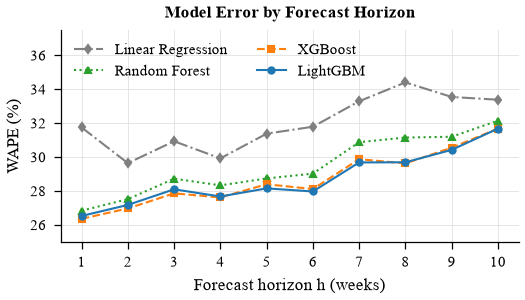

In [14]:
fig, ax = plt.subplots(figsize=(ONE_COL, 2.0))
ax.plot(wape_h.index, wape_h['Linear Regression'], color='grey', linestyle='-.', marker='d', markersize=3, label='Linear Regression')
ax.plot(wape_h.index, wape_h['Random Forest'], color='tab:green', linestyle=':', marker='^', markersize=3, label='Random Forest')
ax.plot(wape_h.index, wape_h['XGBoost'], color='tab:orange', linestyle='--', marker='s', markersize=3, label='XGBoost')
ax.plot(wape_h.index, wape_h['LightGBM'], color='tab:blue', marker='o', markersize=3, label='LightGBM')
ax.set_title('Model Error by Forecast Horizon')
ax.set_xlabel('Forecast horizon h (weeks)')
ax.set_ylabel('WAPE (%)')
ax.set_xticks(range(1, 11))
ax.set_ylim(25, 37.5)
ax.legend(ncol=2, loc='upper left')
save_fig(fig, 'fig23_tree_wape_by_horizon')
plt.show()

### Which features matter? (LightGBM, last fold)

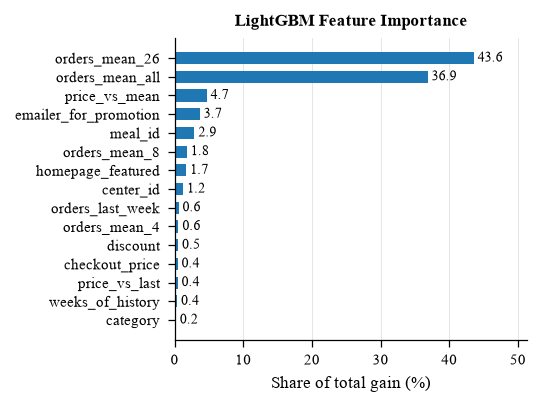

orders_mean_26           43.56
orders_mean_all          36.85
price_vs_mean             4.66
emailer_for_promotion     3.67
meal_id                   2.89
orders_mean_8             1.79
homepage_featured         1.70
center_id                 1.25
orders_last_week          0.57
orders_mean_4             0.55
discount                  0.50
checkout_price            0.43
price_vs_last             0.43
weeks_of_history          0.36
category                  0.18
base_price                0.16
city_code                 0.16
orders_last_known         0.11
cuisine                   0.09
orders_std_8              0.03
weeks_since_seen          0.02
op_area                   0.01
region_code               0.01
center_type               0.00
h                         0.00
dtype: float64

In [15]:
imp = (importance / importance.sum() * 100).sort_values()
top = imp.tail(15)

fig, ax = plt.subplots(figsize=(ONE_COL, 2.6))
ax.barh(top.index, top.values, color='tab:blue', height=0.65)
for i, v in enumerate(top.values):
    ax.text(v, i, f' {v:.1f}', va='center', fontsize=6.5)
ax.set_title('LightGBM Feature Importance')
ax.set_xlabel('Share of total gain (%)')
ax.set_xlim(0, top.max() * 1.18)
ax.grid(axis='y', visible=False)
save_fig(fig, 'fig24_lightgbm_importance')
plt.show()

imp.sort_values(ascending=False).round(2)

### Example: forecast vs actual for one series (last fold)

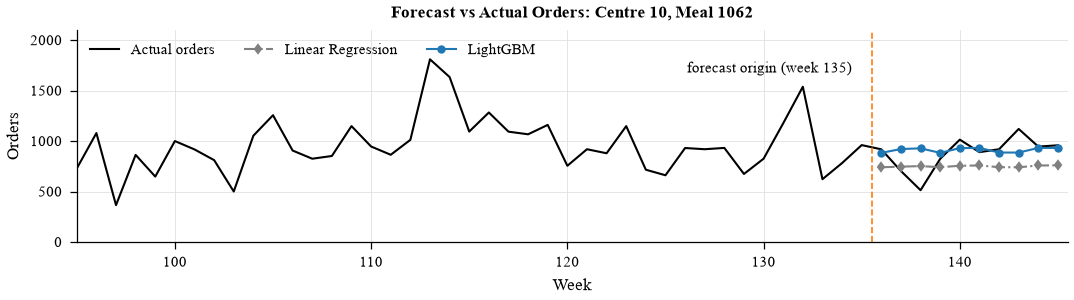

In [16]:
example_id = 101062      # centre 10, meal 1062 - a large series with all weeks
actual = df[df['series_id'] == example_id].set_index('week')['num_orders']
fc = all_preds[(all_preds['series_id'] == example_id) & (all_preds['origin'] == 135)].set_index('week')

fig, ax = plt.subplots(figsize=(TWO_COL, 2.0))
ax.plot(actual.loc[95:].index, actual.loc[95:].values, color='black', linewidth=1, label='Actual orders')
ax.plot(fc.index, fc['Linear Regression'], color='grey', linestyle='-.', marker='d', markersize=3, label='Linear Regression')
ax.plot(fc.index, fc['LightGBM'], color='tab:blue', marker='o', markersize=3, label='LightGBM')
ax.axvline(135.5, color='tab:orange', linestyle='--', linewidth=0.8)
ax.text(134.5, ax.get_ylim()[1] * 0.95, 'forecast origin (week 135)', ha='right', va='top', fontsize=7)
ax.set_title('Forecast vs Actual Orders: Centre 10, Meal 1062')
ax.set_xlabel('Week')
ax.set_ylabel('Orders')
ax.set_xlim(95, 145.5)
ax.set_ylim(0, 2100)
ax.legend(ncol=3, loc='upper left')
save_fig(fig, 'fig25_example_forecast')
plt.show()

## 5. Save

In [17]:
results.to_csv('../results/tables/05_results_per_fold.csv', index=False)
summary.round(3).to_csv('../results/tables/05_results_mean.csv')
dm_table.to_csv('../results/tables/05_diebold_mariano.csv', index=False)
print('saved')

saved


## Summary

| Model | WAPE (mean of 3 folds) | RMSE | RMSLE | Bias | Over-forecast % |
|---|---|---|---|---|---|
| Linear Regression (best baseline) | 32.0% | 183 | 0.51 | -28 | 46% |
| Random Forest | 29.4% | 164 | 0.49 | -26 | 45% |
| XGBoost | 28.65% | 152 | 0.49 | -23 | 46% |
| **LightGBM** | **28.65%** | 152 | 0.49 | -22 | 46% |

**RQ1 answer: yes.** All three tree models beat every baseline in every fold.
- LightGBM and XGBoost reduce WAPE by about **10.5%** compared with Linear Regression (32.0% -> 28.65%),
  Random Forest by 8.1%.
- Diebold-Mariano test: all three tree models are significantly better than Linear Regression (p < 0.001).
  LightGBM and XGBoost are **not** significantly different from each other (p = 0.95); both are significantly
  better than Random Forest (p < 0.001). Random Forest was trained on a 1M-row sample, which may explain part of the gap.
- The gain holds at every horizon. Error grows from about 26.5% (1 week ahead) to 31.7% (10 weeks ahead).
- Tuning picked small numbers of trees (90-250) with early stopping, so the models are not overfitting the training weeks.
- Fold 2 (weeks 126-135) is again the hardest for every model.

**Feature importance (LightGBM):** the 26-week and all-time averages carry about 80% of the gain, then
price relative to the usual price (4.7%) and the email promotion (3.7%). Last week's orders matter very little
(0.6%), which agrees with the low autocorrelation found in notebook 02 and with the choice of features in notebook 03.

**Still biased low:** like the baselines, every tree model forecasts too low on average (bias -22 to -26 orders,
only 45-46% of forecasts are above the actual value). Used as order quantities, these forecasts would cause more
shortages than waste. This is the motivation for the quantile models in notebook 06.

LightGBM is used as the main model for the quantile and simulation steps (best WAPE, fastest to train:
1.5-3 min per fold vs 3-7 min for XGBoost and 6-9 min for Random Forest).

Saved: `results/tables/05_results_per_fold.csv`, `05_results_mean.csv`, `05_diebold_mariano.csv`, `05_best_params.csv`,
`05_lightgbm_importance.csv`, `data/processed/predictions_trees.parquet`.
